# Task 2 (Day 2): Build a reusable feature pipeline
**Objective.** Choose safe input columns, bring in attendance and payroll features, and package all cleaning into one pipeline.
**Why it matters.** A pipeline makes experiments repeatable, stops training and test data from mixing, and the same code scores new people later.
**You will learn.** `Pipeline`, `ColumnTransformer`, imputation, encoding, scaling, fitting on training data only, creating a useful new feature.
Pipeline code: `src/cortexhr/features.py` (reusable outside notebooks). All 12 workflow stages are shown below.

In [1]:
import sys, pathlib, inspect, subprocess
ROOT = pathlib.Path.cwd().resolve()
while not (ROOT / 'src').exists(): ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'src'))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 60); pd.set_option('display.max_colwidth', 110)
from sklearn.model_selection import cross_val_predict
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import roc_auc_score, average_precision_score, precision_score, recall_score, f1_score, accuracy_score, confusion_matrix
from cortexhr import config as C, data_loading as D, audit as A, features as F, modeling as M, evaluation as E, reporting as R, runs, workflow as W
print('Python', sys.version.split()[0], '| project root:', ROOT)

Python 3.12.3 | project root: /home/claude/cortexhr_phase1


In [2]:
mk = lambda est, monthly=False: Pipeline([('features', F.build_pipeline(monthly)), ('model', est)])
LRB = lambda **kw: LogisticRegression(class_weight='balanced', max_iter=2000, random_state=C.SEED, **kw)
def metrics_row(y, s, thr=0.5):
    r = E.binary_report(y, s, threshold=thr); return {k: r[k] for k in ['roc_auc', 'pr_auc', 'precision', 'recall', 'f1', 'accuracy', 'top_precision', 'top_recall']}

---
# Stage 1 of 12: Data Collection
Three tables are needed: attrition rows plus monthly attendance and payroll.

In [3]:
raw = D.load_attrition(); att = D.load_sheet(C.SHEET_ATT); pay = D.load_sheet(C.SHEET_PAY)
pd.DataFrame({'table': ['attrition_dataset', 'attendance_monthly_features', 'payroll_monthly_features'], 'rows': [len(raw), len(att), len(pay)],
              'columns': [raw.shape[1], att.shape[1], pay.shape[1]], 'employees': [raw.employee_id.nunique(), att.employee_id.nunique(), pay.employee_id.nunique()]})

                         table  rows  columns  employees
0            attrition_dataset  2389       42       2383
1  attendance_monthly_features  7339       16        528
2     payroll_monthly_features  7355       23        528

---
# Stage 2 of 12: Data Understanding
Granularity and join keys.

In [4]:
print('attendance months', att.month.min().date(), '->', att.month.max().date(), '| one row per employee and month')
print('join key: employee_id (+ observation_date cutoff)')
att.head(3)

attendance months 2025-04-01 -> 2026-09-01 | one row per employee and month
join key: employee_id (+ observation_date cutoff)


  attendance_feature_id employee_id      month department_id  job_level  scheduled_days  present_days  wfh_days  half_days_unpaid  paid_leave_days  unpaid_absence_days  longest_unpaid_streak_days  \
0              AF-00001    EMP-0002 2025-04-01           D08          4              20            20        18                 0                0                    0                           0   
1              AF-00002    EMP-0002 2025-05-01           D08          4              21            20        18                 1                0                    0                           0   
2              AF-00003    EMP-0002 2025-06-01           D08          4              21            19        18                 1                1                    0                           0   

   late_arrivals  avg_hours_worked  overtime_hours  attendance_rate  
0              1              8.50             0.0           1.0000  
1              2              8.71             0.0           0.

In [5]:
pay.head(3)

  payroll_item_id      run_id employee_id      month department_id role_id  job_level overtime_eligible  monthly_fixed_gross  payable_days  lop_days  overtime_hours_paid  overtime_pay  variable_pay  \
0       PI-000001  PR-2025-04    EMP-0002 2025-04-01           D08    R047          4                 N             144460.0          30.0       0.0                  0.0           0.0      34670.40   
1       PI-000002  PR-2025-04    EMP-0004 2025-04-01           D03    R017          3                 N             103938.0          30.0       0.0                  0.0           0.0      56126.52   
2       PI-000003  PR-2025-04    EMP-0006 2025-04-01           D00    R001          7                 N             479009.0          30.0       0.0                  0.0           0.0          0.00   

   variable_pay_type  gross_pay  pf_employee  esi_employee  professional_tax        tds  other_deductions  total_deductions    net_pay  
0  Performance Bonus  179130.40       1800.0           0.0

In [6]:
cover = raw.assign(in_att=raw.employee_id.isin(att.employee_id)).groupby('source').in_att.agg(['sum', 'count'])
cover   # only the master snapshot rows have monthly history

                          sum  count
source                              
historical_extension        0   2000
master_employee_snapshot  389    389

---
# Stage 3 of 12: Data Quality Audit
Audit of the monthly tables.

In [7]:
iss = {'attendance duplicate (employee, month)': int(att.duplicated(['employee_id', 'month']).sum()),
       'payroll exact duplicate rows': D.dedupe_payroll(pay)[1],
       'attendance months after the 30 Sep 2025 snapshot (future)': int((att.month > pd.Timestamp('2025-09-30')).sum()),
       'attendance_rate above 1': int((att.attendance_rate > 1).sum()), 'present_days above scheduled_days': int((att.present_days > att.scheduled_days).sum()),
       'wfh_days above present_days': int((att.wfh_days > att.present_days).sum()), 'missing values (attendance)': int(att.isna().sum().sum()),
       'missing values (payroll)': int(pay.isna().sum().sum())}
pd.Series(iss, name='count').to_frame()

                                                           count
attendance duplicate (employee, month)                         0
payroll exact duplicate rows                                  15
attendance months after the 30 Sep 2025 snapshot (future)   4985
attendance_rate above 1                                        0
present_days above scheduled_days                              0
wfh_days above present_days                                   19
missing values (attendance)                                    0
missing values (payroll)                                    6202

**Decision.** Use only complete months that ended on or before `observation_date` (Jul-Sep 2025 for the 30 Sep 2025 snapshot); later months are future information. Remove exact duplicate payroll rows so no month is counted twice.

---
# Stage 4 of 12: Exploratory Data Analysis (EDA)
Do the recent attendance/payroll aggregates differ between leavers and stayers?

In [8]:
prepared, plog = D.prepare_attrition(raw)
joined, rep = D.join_monthly_features(prepared, att, pay)
matched = joined[joined.att_months_covered.notna()]
print(len(matched), 'rows have monthly history;', int(matched[C.TARGET].sum()), 'of them left')
W.numeric_vs_target(matched, C.MONTHLY_ALL)

383 rows have monthly history; 50 of them left


left_within_12m              mean_stayed  mean_left  relative_diff_pct
att_half_days_sum_3m               0.261      0.360               37.8
pay_lop_days_sum_3m                0.655      0.880               34.4
att_unpaid_absence_sum_3m          0.937      1.120               19.5
pay_overtime_pay_mean_3m         483.538    407.922              -15.6
pay_variable_share_3m              0.027      0.023              -15.0
att_overtime_mean_3m               1.380      1.452                5.2
att_late_arrivals_sum_3m           4.147      4.360                5.1
att_wfh_share_3m                   0.426      0.416               -2.3
att_attendance_rate_mean_3m        0.946      0.955                0.9
pay_variable_pay_mean_3m        4085.936   4047.198               -0.9
pay_net_to_gross_3m                0.934      0.939                0.6
att_avg_hours_mean_3m              8.475      8.487                0.1

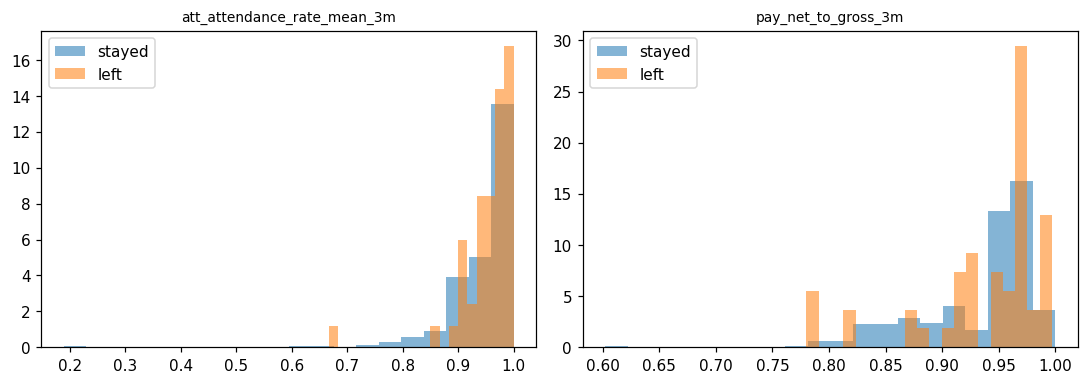

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for ax, c in zip(axes, ['att_attendance_rate_mean_3m', 'pay_net_to_gross_3m']):
    for v, lab in [(0, 'stayed'), (1, 'left')]: ax.hist(matched.loc[matched[C.TARGET] == v, c].dropna(), bins=20, alpha=.55, label=lab, density=True)
    ax.set_title(c, fontsize=9); ax.legend()
fig.tight_layout();

**EDA reading.** Differences between leavers and stayers in the 3-month aggregates are small (and only 383 rows have them), so expect little gain from these features.

---
# Stage 5 of 12: Data Cleaning
Deduplicate payroll, apply the cutoff, validate the join.

In [10]:
pay_clean, n_dup = D.dedupe_payroll(pay); print('payroll rows', len(pay), '->', len(pay_clean), '(removed', n_dup, 'exact duplicates)')
S = runs.load_model_frame(include_monthly=True)
pd.Series(S['join_report'], name='value').to_frame()

payroll rows 7355 -> 7340 (removed 15 exact duplicates)


                                                                                                               value
rows_before_join                                                                                                2383
rows_after_join                                                                                                 2383
cardinality                                                      attrition(1) -> aggregates(1), validated one_to_one
attendance_matched_rows                                                                                          383
payroll_matched_rows                                                                                             383
unmatched_rows_attendance                                                                                       2000
unmatched_rows_payroll                                                                                          2000
rows_dropped                                                    

In [11]:
emp = S['df'].loc[S['df'].att_months_covered.notna(), 'employee_id'].iloc[0]
print('Example employee', emp, '- all attendance months in the file:')
print(att[att.employee_id == emp][['month', 'attendance_rate', 'late_arrivals', 'unpaid_absence_days']].to_string(index=False))
print('\nAggregated (cutoff 2025-09-30, only Jul-Sep used):')
S['df'].loc[S['df'].employee_id == emp, ['observation_date', 'att_attendance_rate_mean_3m', 'att_late_arrivals_sum_3m', 'att_months_covered']]

Example employee EMP-0002 - all attendance months in the file:
     month  attendance_rate  late_arrivals  unpaid_absence_days
2025-04-01           1.0000              1                    0
2025-05-01           0.9762              2                    0
2025-06-01           0.9286              1                    0
2025-07-01           1.0000              1                    0
2025-08-01           1.0000              1                    0
2025-09-01           0.7727              1                    1
2025-10-01           0.9500              1                    1
2025-11-01           0.9500              1                    0
2025-12-01           0.9545              1                    0
2026-01-01           1.0000              1                    0
2026-02-01           1.0000              0                    0
2026-03-01           1.0000              0                    0
2026-04-01           1.0000              2                    0
2026-05-01           0.9500              

  observation_date  att_attendance_rate_mean_3m  att_late_arrivals_sum_3m  att_months_covered
0       2025-09-30                     0.924233                       3.0                 3.0

---
# Stage 6 of 12: Feature Engineering
Aggregates, derived features, and the pipeline code itself.

In [12]:
print('Drop / keep / transform decisions:'); A.column_roles(raw).groupby('decision').column.apply(list).to_frame()

Drop / keep / transform decisions:


                                                                                                                  column
decision                                                                                                                
DROP       [row_id, employee_id, observation_date, voluntary_left_within_12m, source, exit_date, resignation_date, ex...
RETAIN     [job_level, previous_employers_count, commute_distance_km, comp_ratio, raises_received, last_raise_pct, mo...
TARGET                                                                                                 [left_within_12m]
TRANSFORM  [department_id, role_id, work_location, work_mode, employment_type, highest_education, tenure_months, tota...

In [13]:
pd.DataFrame(F.FEATURE_DOCS, columns=['feature', 'source', 'definition', 'temporal cutoff'])

                        feature                       source                                                                                  definition                            temporal cutoff
0            pay_vs_dept_median                      derived  annual pay / median pay of same department+job level; medians fitted on training rows only               snapshot at observation_date
1        raise_stagnation_ratio                      derived                                               months_since_last_raise / (tenure_months + 1)               snapshot at observation_date
2                never_promoted                      derived              1 if promotions_received == 0 (explains the blank months_since_last_promotion)               snapshot at observation_date
3                log_annual_pay                      derived                       log1p(annual_fixed_pay) after blanking pay-typos (>3x role mid-point)               snapshot at observation_date
4   att_attendance_r

In [14]:
print(inspect.getsource(F.build_pipeline))

def build_pipeline(include_monthly: bool = True) -> Pipeline:
    num, monthly, cat = feature_lists(include_monthly)
    blocks = [("num", Pipeline([("impute", SimpleImputer(strategy="median", add_indicator=True)),
                                ("scale", StandardScaler())]), num)]
    if monthly:
        blocks.append(("monthly", Pipeline([("impute", SimpleImputer(strategy="median")),
                                            ("scale", StandardScaler())]), monthly))
    blocks.append(("cat", Pipeline([("impute", SimpleImputer(strategy="constant", fill_value="Unknown")),
                                    ("onehot", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=15,
                                                             sparse_output=False))]), cat))
    prep = ColumnTransformer(blocks, remainder="drop", verbose_feature_names_out=False)
    prep.set_output(transform="pandas")          # clean/derive already return DataFrames
    return Pipeline([("clean", R

In [15]:
print(inspect.getsource(F.Derive))

class Derive(BaseEstimator, TransformerMixin):
    """Derived features. Reference statistics are learned in fit() on training rows only.

    pay_vs_dept_median : annual pay / median pay of the same department+job level (fallback: department, then all)
    raise_stagnation_ratio : months since last raise / (tenure + 1)  - stuck pay relative to time in company
    never_promoted : 1 if promotions_received == 0
    log_annual_pay : log1p(pay) after blanking pay-typos (pay > typo_factor x its role mid-point)
    """
    def __init__(self, typo_factor: float = 3.0):
        self.typo_factor = typo_factor

    def _implied_mid(self, X): return X["annual_fixed_pay"] / X["comp_ratio"]

    def fit(self, X, y=None):
        X = pd.DataFrame(X)
        self.role_mid_ = self._implied_mid(X).groupby(X["role_id"]).median().to_dict()
        pay = self._fix_pay(X)
        self.grp_median_ = pay.groupby([X["department_id"], X["job_level"]]).median().to_dict()
        self.dept_median_ = pay.groupby(

---
# Stage 7 of 12: Train-Test Split
Stratified split first; then every learned number comes from TRAINING rows only.

In [16]:
Xtr, ytr, Xte, yte, folds = S['Xtr'], S['ytr'], S['Xte'], S['yte'], S['folds']
print('X:', S['X'].shape, '| target in X?', C.TARGET in S['X'].columns, '| train', Xtr.shape, 'test', Xte.shape)
pipe = F.build_pipeline(True).fit(Xtr, ytr)               # fit sees training rows only
d = pipe.named_steps['derive']
print('department-pay medians learned from', len(Xtr), 'training rows:', len(d.grp_median_), 'dept+level groups | global median pay =', d.global_median_)
print('the', len(Xte), 'test rows influenced none of these numbers')

X: (2383, 43) | target in X? False | train (1906, 43) test (477, 43)
department-pay medians learned from 1906 training rows: 51 dept+level groups | global median pay = 767850.0
the 477 test rows influenced none of these numbers


**Why fit on training data only (3 lines).** 1) Medians, means, categories and department pay medians describe the data; computing them on test rows leaks test information into training. 2) A new employee scored tomorrow is not in the data the pipeline learned from, so the honest test is data it never saw. 3) Putting the pipeline inside `Pipeline.fit()` (and inside every CV fold) guarantees it.

---
# Stage 8 of 12: Model Building
Plug the pipeline into a model, then test with 3 raw rows, unseen categories and missing values.

In [17]:
raw3 = F.representative_rows(S['df'])
print(raw3[['row_id', 'tenure_months', 'work_location', 'last_engagement_score']].to_string(index=False))
Z = pipe.transform(raw3[F.input_columns(True)])
print('\n3 raw rows ->', Z.shape, '| all numbers finite:', bool(np.isfinite(Z.to_numpy()).all()), '| target in output:', any('left_within' in c for c in Z.columns))
Z.iloc[:, :8]

 row_id  tenure_months work_location  last_engagement_score
    109             -4       Chennai                    5.0
      1            164          Pune                    2.5
      2            162         Erode                    2.4

3 raw rows -> (3, 137) | all numbers finite: True | target in output: False


     job_level  tenure_months  total_experience_years  previous_employers_count  commute_distance_km  comp_ratio  raises_received  last_raise_pct
108  -0.440634      -0.241674               -0.142866                 -0.184753             0.036646   -0.072364         1.058797       -0.753788
0     1.318210       4.670827                5.073470                 -0.184753            -0.027103   -0.336829         2.294223       -0.938350
1     0.438788       4.596955                2.030608                 -0.184753            -0.282097   -1.328571         2.294223       -0.177033

In [18]:
t = raw3[F.input_columns(True)].copy()
t.iloc[0, t.columns.get_loc('role_id')] = 'R999'; t.iloc[1, t.columns.get_loc('department_id')] = np.nan; t.iloc[2, t.columns.get_loc('comp_ratio')] = np.nan
print('unseen category + missing values handled:', bool(np.isfinite(pipe.transform(t).to_numpy()).all()))
full_lr = mk(LRB(), True)

unseen category + missing values handled: True


In [19]:
import joblib
joblib.dump(pipe, ROOT / 'artifacts' / 'models' / 'feature_pipeline_notebook.joblib')
print('saved fitted pipeline; reload with joblib.load(...).transform(new_rows)')

saved fitted pipeline; reload with joblib.load(...).transform(new_rows)


---
# Stage 9 of 12: Model Evaluation
Does the pipeline work end to end? Cross-validated metrics and confusion matrix.

In [20]:
oof_full = cross_val_predict(full_lr, Xtr, ytr, cv=folds, method='predict_proba')[:, 1]
Xc, _ = F.make_xy(S['df'], False)
oof_core = cross_val_predict(mk(LRB(), False), Xc.loc[Xtr.index], ytr, cv=folds, method='predict_proba')[:, 1]
pd.DataFrame({'with attendance+payroll features': metrics_row(ytr, oof_full), 'attrition-table features only': metrics_row(ytr, oof_core)}).T.round(3)

                                  roc_auc  pr_auc  precision  recall     f1  accuracy  top_precision  top_recall
with attendance+payroll features    0.697   0.294      0.247   0.573  0.345     0.681          0.377       0.258
attrition-table features only       0.705   0.296      0.249   0.595  0.351     0.678          0.366       0.251

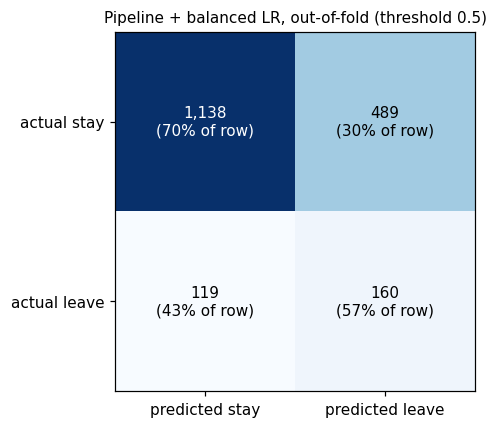

In [21]:
W.plot_confusion(ytr, oof_full, 0.5, 'Pipeline + balanced LR, out-of-fold');

In [22]:
has = S['df'].loc[Xtr.index, 'att_months_covered'].notna().to_numpy()
print('Rows with monthly history in training:', int(has.sum()), 'leavers:', int(ytr[has].sum()))
print('OOF ROC-AUC on those rows only -> with monthly:', round(roc_auc_score(ytr[has], oof_full[has]), 3), '| without:', round(roc_auc_score(ytr[has], oof_core[has]), 3))

Rows with monthly history in training: 315 leavers: 41
OOF ROC-AUC on those rows only -> with monthly: 0.665 | without: 0.699


---
# Stage 10 of 12: Hyperparameter Tuning
Which aggregation window works best? (3 months was the brief's example.) Evaluated on rows that have monthly history, CV only.

In [23]:
from sklearn.model_selection import StratifiedKFold
rows = []
for w in [1, 3, 6]:
    jw, _ = D.join_monthly_features(prepared, att, pay, window=w); Xw, yw = F.make_xy(jw, True)
    mk_idx = jw.att_months_covered.notna().to_numpy(); Xm, ym = Xw[mk_idx], yw[mk_idx]
    ff = list(StratifiedKFold(5, shuffle=True, random_state=C.SEED).split(Xm, ym))
    s = cross_val_predict(mk(LRB(), True), Xm, ym, cv=ff, method='predict_proba')[:, 1]
    rows.append({'window_months': w, 'rows': len(Xm), 'leavers': int(ym.sum()), 'cv_roc_auc': round(roc_auc_score(ym, s), 3)})
pd.DataFrame(rows)

   window_months  rows  leavers  cv_roc_auc
0              1   383       50       0.630
1              3   383       50       0.635
2              6   383       50       0.667

Only ~380 rows (about 50 leavers) are available, so differences between windows are noise-level; the brief's 3-month window is kept.

---
# Stage 11 of 12: Model Interpretation
Which engineered features matter? Plus the 'think for yourself' feature.

In [24]:
fit_full = full_lr.fit(Xtr, ytr)
W.logreg_coefficients(fit_full, 12)

                                 feature  coefficient
0                           role_id_R012    -1.813289
1     highest_education_M.A. Social Work    -1.620387
2                           role_id_R044    -1.587051
3                           role_id_R015    -1.476786
4                           role_id_R018     1.133308
5                      department_id_D10    -1.069669
6                           role_id_R046     1.011867
7                           role_id_R041     1.007473
8                           role_id_R042    -0.989344
9             role_id_infrequent_sklearn    -0.939251
10                 highest_education_LLM    -0.935200
11  highest_education_infrequent_sklearn     0.886162

In [25]:
cf = W.logreg_coefficients(fit_full, 200); cf[cf.feature.isin(F.NUMERIC_DERIVED if hasattr(F, 'NUMERIC_DERIVED') else F.NUMERIC_DERIVED)]

                    feature  coefficient
50           log_annual_pay     0.404494
95   raise_stagnation_ratio    -0.117766
122      pay_vs_dept_median    -0.024699
128          never_promoted     0.014701

### Think for yourself: one new feature an HR manager would find sensible
`pay_vs_dept_median` = my pay divided by the median pay of colleagues in the same department and level (medians learned on training rows). **Why it can help:** people paid below their peers are more likely to look elsewhere, and comparing with peers is fairer than raw salary. Check on training rows:

In [26]:
dv = pipe.named_steps['derive'].transform(pipe.named_steps['clean'].transform(Xtr))
q = pd.qcut(dv.pay_vs_dept_median, 4, duplicates='drop')
pd.crosstab(q, ytr.to_numpy(), normalize='index').round(3).rename(columns={0: 'stayed', 1: 'left'})

col_0               stayed   left
pay_vs_dept_median               
(0.503, 0.911]       0.847  0.153
(0.911, 1.0]         0.828  0.172
(1.0, 1.103]         0.843  0.157
(1.103, 1.834]       0.897  0.103

---
# Stage 12 of 12: Final Conclusions and Recommendations
Summary, limits and next steps.

In [27]:
print(f'''PIPELINE: {S['X'].shape[1]} raw inputs -> {Z.shape[1]} model-ready columns; fitted on {len(Xtr)} training rows only; handles unseen categories and missing values.
JOIN: {S['join_report']['attendance_matched_rows']} of {S['join_report']['rows_after_join']} rows have monthly history; 0 rows dropped; cardinality validated 1:1.
RESULT: LR ROC-AUC {roc_auc_score(ytr, oof_full):.3f} with monthly features vs {roc_auc_score(ytr, oof_core):.3f} without -> the monthly aggregates add little because 84% of rows lack them.
RECOMMENDATIONS: 1) request monthly history for the 2,000 historical rows; 2) keep the cutoff rule (no future months); 3) reuse build_pipeline() for scoring so training and scoring never diverge.''')

PIPELINE: 43 raw inputs -> 137 model-ready columns; fitted on 1906 training rows only; handles unseen categories and missing values.
JOIN: 383 of 2383 rows have monthly history; 0 rows dropped; cardinality validated 1:1.
RESULT: LR ROC-AUC 0.697 with monthly features vs 0.705 without -> the monthly aggregates add little because 84% of rows lack them.
RECOMMENDATIONS: 1) request monthly history for the 2,000 historical rows; 2) keep the cutoff rule (no future months); 3) reuse build_pipeline() for scoring so training and scoring never diverge.


### Completion checklist (checked by code)

In [28]:
checks = {
    "'No leaking column enters the pipeline'": not any(any(b in c for b in C.LEAKAGE_CONFIRMED) for c in Z.columns),
    "'Target column is never used as an input'": C.TARGET not in S['X'].columns,
    "'3-row test passes (finite numbers)'": Z.shape[0] == 3 and bool(np.isfinite(Z.to_numpy()).all()),
    "'Join keeps one row per attrition row'": S['join_report']['rows_before_join'] == S['join_report']['rows_after_join'],
    "'Learned statistics come from training rows only'": d.global_median_ == float(d._fix_pay(pd.DataFrame(Xtr)).median()),
    "'I can explain fit on training only (3 lines above)'": True
}
status = {k: ('MANUAL' if isinstance(v, str) and v == 'MANUAL' else 'PASS' if bool(v) else 'FAIL') for k, v in checks.items()}
for k, v in status.items(): print(f'[{v}]', k)
assert 'FAIL' not in status.values()

[PASS] 'No leaking column enters the pipeline'
[PASS] 'Target column is never used as an input'
[PASS] '3-row test passes (finite numbers)'
[PASS] 'Join keeps one row per attrition row'
[PASS] 'Learned statistics come from training rows only'
[PASS] 'I can explain fit on training only (3 lines above)'


### Evidence for your report
Pipeline code link (GitHub): `src/cortexhr/features.py` | 3-row test output: Stage 8 cell above and `pytest -v` (`test_three_row_smoke_unseen_and_missing`)
References: [scikit-learn](https://github.com/scikit-learn/scikit-learn) | [pandas](https://github.com/pandas-dev/pandas) | [pytest](https://github.com/pytest-dev/pytest)
**How real companies do it:** the very same pipeline code that trained a model also scores new people; copy-pasted preprocessing is a classic source of silent errors.
**Connects to Task 3:** the pipeline prepares the data; next we train the first models on it.
**You can now say:** *I built a reusable feature pipeline with no leakage.*